# Iris Flower Classification

## Project Overview
Iris Flower Classification is a Machine Learning project
that predicts the species of an Iris flower based on its
physical measurements.

## Project Objective
The main objective is to build a Machine Learning model
that can classify Iris flowers into three different species.

## Iris Flower Species
1. Iris Setosa
2. Iris Versicolor
3. Iris Virginica

## Technologies Used
- Python
- NumPy
- Pandas
- Matplotlib
- Seaborn
- Scikit-learn
- Jupyter Notebook


In [188]:
# Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris

print("All libraries imported successfully!")

All libraries imported successfully!


In [189]:
# Load the Iris Flower Dataset

iris_data = load_iris()

# Convert the dataset into a Pandas DataFrame
df = pd.DataFrame(
    data=iris_data.data,
    columns=iris_data.feature_names
)

# Add flower species names
df["species"] = pd.Categorical.from_codes(
    iris_data.target,
    iris_data.target_names
)

print("Iris Dataset Loaded Successfully!")


Iris Dataset Loaded Successfully!


In [190]:
# Load the Iris Flower Dataset

iris_data = load_iris()

# Convert dataset into a DataFrame
df = pd.DataFrame(
    iris_data.data,
    columns=iris_data.feature_names
)

# Add flower species names
df["species"] = pd.Categorical.from_codes(
    iris_data.target,
    iris_data.target_names
)

print("Iris Dataset Loaded Successfully!")

Iris Dataset Loaded Successfully!


In [191]:
# Display the first five rows of the dataset

print("First Five Rows of the Dataset:")
display(df.head())

# Display the dataset size
print("Dataset Shape:", df.shape)

First Five Rows of the Dataset:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


Dataset Shape: (150, 5)


In [192]:
# Check dataset information

print("Dataset Information:")
df.info()

print("\nMissing Values in Each Column:")
print(df.isnull().sum())

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype   
---  ------             --------------  -----   
 0   sepal length (cm)  150 non-null    float64 
 1   sepal width (cm)   150 non-null    float64 
 2   petal length (cm)  150 non-null    float64 
 3   petal width (cm)   150 non-null    float64 
 4   species            150 non-null    category
dtypes: category(1), float64(4)
memory usage: 5.0 KB

Missing Values in Each Column:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64


In [193]:
# Statistical analysis of Iris dataset

print("Statistical Summary:")
display(df.describe())

Statistical Summary:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


Average Measurements of Each Species:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
species,,,,
setosa,5.006,3.428,1.462,0.246
versicolor,5.936,2.770,4.260,1.326
virginica,6.588,2.974,5.552,2.026


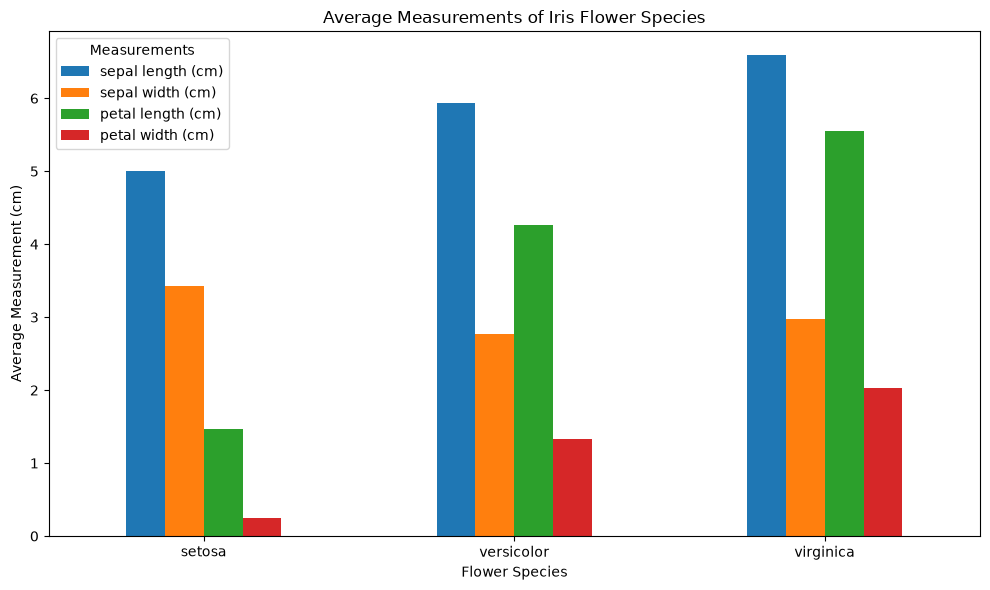

In [194]:
# Compare average measurements of each flower species

species_means = df.groupby(
    "species", observed=True
)[iris_data.feature_names].mean()

print("Average Measurements of Each Species:")
display(species_means)

# Create a comparison graph
species_means.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Average Measurements of Iris Flower Species")
plt.xlabel("Flower Species")
plt.ylabel("Average Measurement (cm)")
plt.xticks(rotation=0)
plt.legend(title="Measurements")
plt.tight_layout()
plt.show()

Number of Flowers in Each Species:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


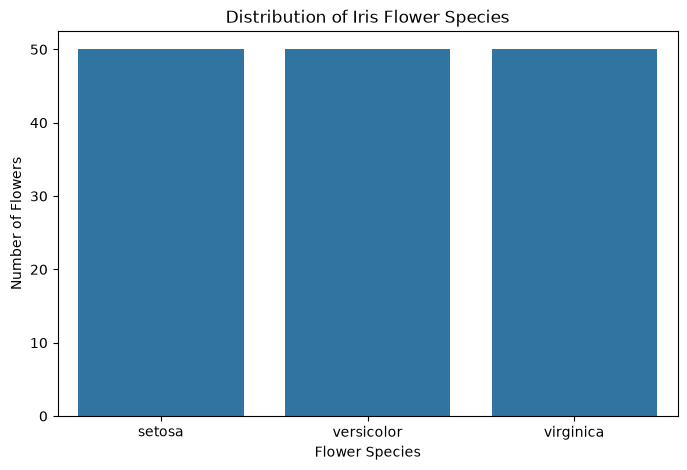

In [195]:
# Count the number of flowers in each species

print("Number of Flowers in Each Species:")
print(df["species"].value_counts())

# Visualize species distribution
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="species")

plt.title("Distribution of Iris Flower Species")
plt.xlabel("Flower Species")
plt.ylabel("Number of Flowers")

plt.show()

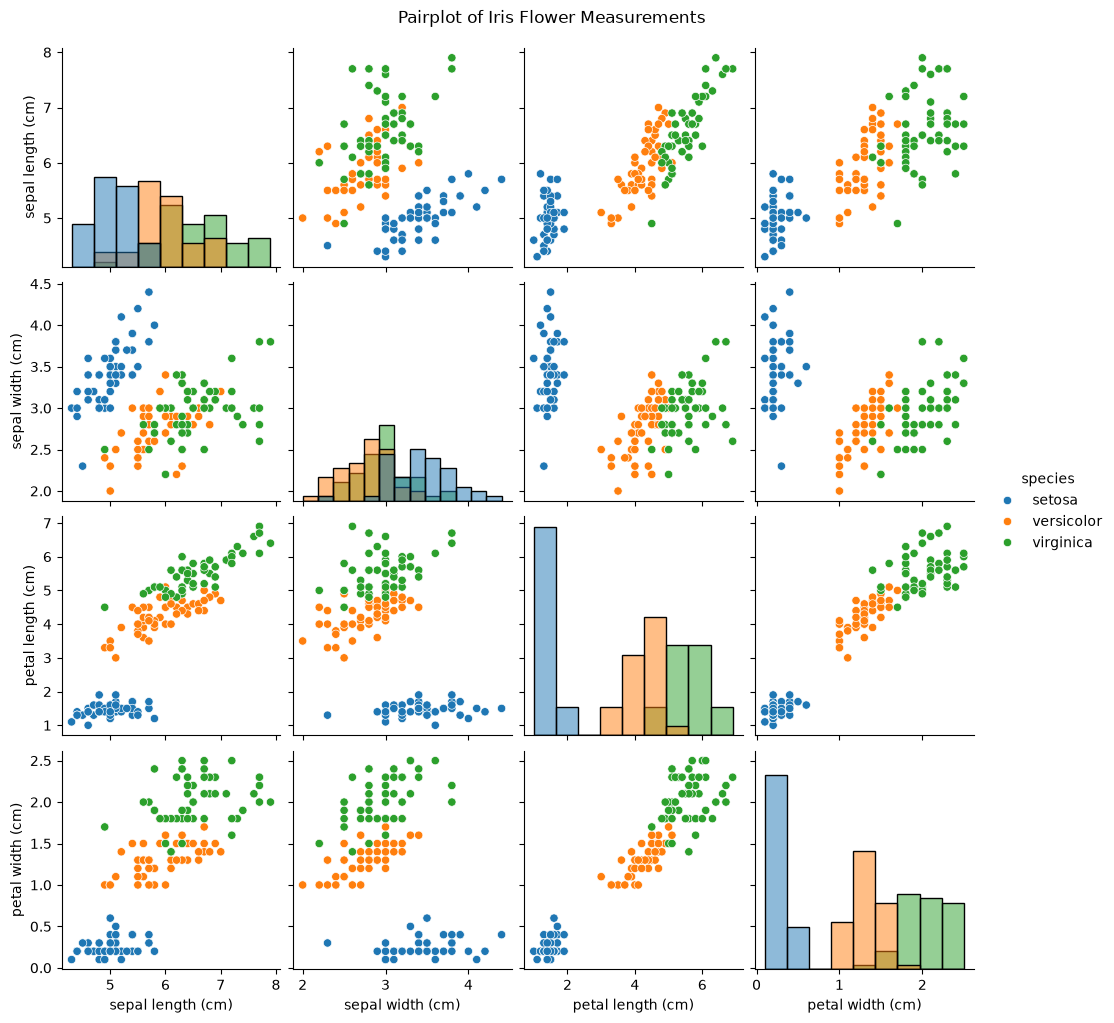

In [196]:
# Visualize relationships between flower measurements

sns.pairplot(
    df,
    hue="species",
    diag_kind="hist"
)

plt.suptitle(
    "Pairplot of Iris Flower Measurements",
    y=1.02
)

plt.show()

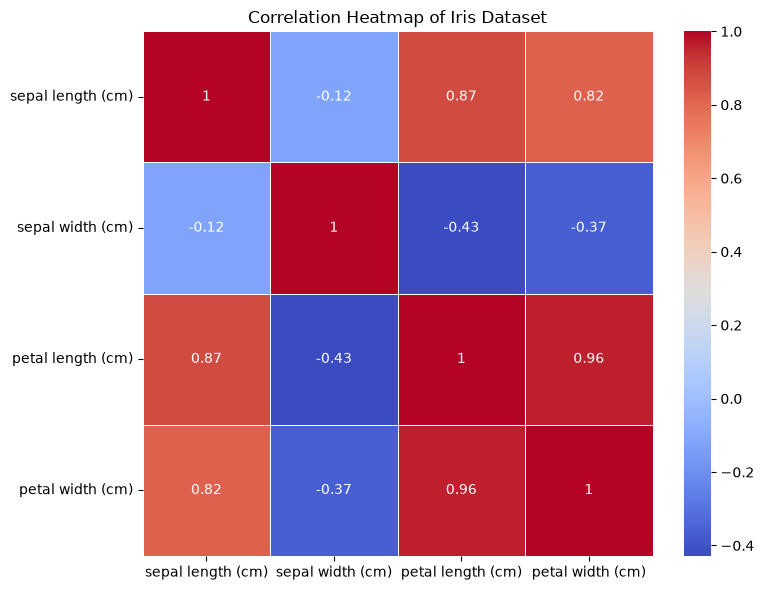

In [197]:
# Create a correlation heatmap

correlation = df.select_dtypes(include="number").corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Iris Dataset")
plt.tight_layout()
plt.show()

In [198]:
# Separate features and target

X = df.drop("species", axis=1)

y = iris_data.target

print("Features and Target Separated Successfully!")

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

display(X.head())

Features and Target Separated Successfully!
Features Shape: (150, 4)
Target Shape: (150,)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [199]:
# Split dataset into training and testing sets

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Dataset Split Successfully!")

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Dataset Split Successfully!
Training Features: (120, 4)
Testing Features: (30, 4)
Training Target: (120,)
Testing Target: (30,)


In [200]:
# Import Random Forest Classifier

from sklearn.ensemble import RandomForestClassifier

# Create the Machine Learning model
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train the model using training data
model.fit(X_train, y_train)

print("Machine Learning Model Trained Successfully!")

Machine Learning Model Trained Successfully!


In [201]:
# Predict flower species using the trained model

y_pred = model.predict(X_test)

# Compare actual and predicted results
comparison = pd.DataFrame({
    "Actual Species": iris_data.target_names[y_test[:10]],
    "Predicted Species": iris_data.target_names[y_pred[:10]]
})

print("Actual vs Predicted Flower Species:")
display(comparison)

Actual vs Predicted Flower Species:


,Actual Species,Predicted Species
0,setosa,setosa
1,virginica,virginica
2,versicolor,versicolor
3,versicolor,versicolor
4,setosa,setosa
5,versicolor,versicolor
6,setosa,setosa
7,setosa,setosa
8,virginica,virginica
9,versicolor,versicolor


In [202]:
# Evaluate the accuracy of our model

from sklearn.metrics import accuracy_score, classification_report

# Calculate model accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")

# Generate classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=iris_data.target_names
))

Model Accuracy: 90.0 %

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.82      0.90      0.86        10
   virginica       0.89      0.80      0.84        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30



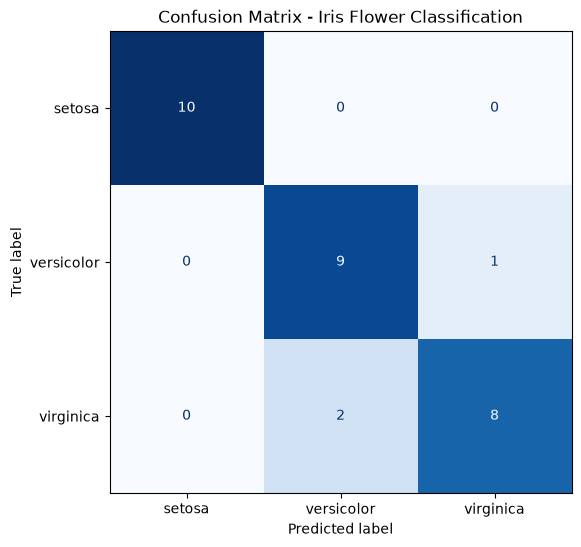

In [203]:
# Create a confusion matrix

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

# Display the confusion matrix
display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=iris_data.target_names
)

fig, ax = plt.subplots(figsize=(8, 6))

display_matrix.plot(
    ax=ax,
    cmap="Blues",
    colorbar=False
)

plt.title("Confusion Matrix - Iris Flower Classification")
plt.show()

In [204]:
# Predict the species of a new Iris flower

new_flower = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=iris_data.feature_names
)

# Make prediction
prediction = model.predict(new_flower)

# Display predicted species
predicted_species = iris_data.target_names[prediction[0]]

print("New Flower Measurements:")
display(new_flower)

print("Predicted Flower Species:", predicted_species)

New Flower Measurements:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2


Predicted Flower Species: setosa


Feature Importance:


,Feature,Importance
3,petal width (cm),0.437185
2,petal length (cm),0.431466
0,sepal length (cm),0.116349
1,sepal width (cm),0.015000


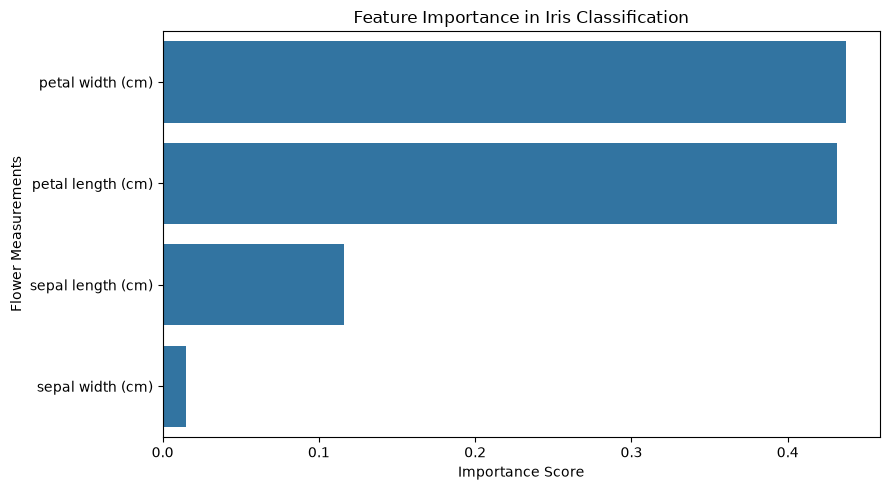

In [205]:
# Check the importance of each flower measurement

importance = pd.DataFrame({
    "Feature": iris_data.feature_names,
    "Importance": model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print("Feature Importance:")
display(importance)

# Create a bar graph
plt.figure(figsize=(9, 5))

sns.barplot(
    data=importance,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance in Iris Classification")
plt.xlabel("Importance Score")
plt.ylabel("Flower Measurements")
plt.tight_layout()
plt.show()

In [206]:
# Final Model Evaluation Summary

from sklearn.metrics import accuracy_score

total_samples = len(y_test)
correct_predictions = (y_test == y_pred).sum()
incorrect_predictions = total_samples - correct_predictions
accuracy = accuracy_score(y_test, y_pred) * 100

results = pd.DataFrame({
    "Evaluation Metric": [
        "Total Testing Samples",
        "Correct Predictions",
        "Incorrect Predictions",
        "Model Accuracy"
    ],
    "Result": [
        total_samples,
        correct_predictions,
        incorrect_predictions,
        f"{accuracy:.2f}%"
    ]
})

print("FINAL MODEL PERFORMANCE")
display(results)

FINAL MODEL PERFORMANCE


,Evaluation Metric,Result
0,Total Testing Samples,30
1,Correct Predictions,27
2,Incorrect Predictions,3
3,Model Accuracy,90.00%


# Conclusion

The Iris Flower Classification project was successfully
implemented using Machine Learning.

In this project, we used the Iris dataset containing 150
flower records and four measurement features.

We performed data analysis, data visualization, and
trained a Random Forest Classification model.

The model achieved an accuracy of 90% on the testing data.

We also tested the model with new flower measurements
and successfully predicted the species as Setosa.

## Final Outcome

- Dataset: Iris Flower Dataset
- Total Samples: 150
- Machine Learning Algorithm: Random Forest Classifier
- Training Data: 80%
- Testing Data: 20%
- Model Accuracy: 90%

This project helped us understand data analysis,
visualization, classification, and model evaluation.